# Сводный анализ и визуализация данных в Pandas/Matplotlib/seaborn/plotly


Разведочный или исследовательский анализ данных (Exploratory Data Analysis, __EDA__) — [это этап работы с данными](https://habr.com/ru/companies/yandex_praktikum/articles/952084/), на котором аналитик изучает доступную информацию перед построением сложных  моделей искусственного интеллекта.  [EDA](https://github.com/ivtipm/ML) включает анализ основных свойств данных, нахождение в них общих закономерностей, распределений и аномалий, постановку начальных гипотез, зачастую с использованием инструментов визуализации.

[Цели разведочного анализа данных](https://habr.com/ru/companies/otus/articles/752434/)

* __Понимание структуры и характеристик набора данных__
На этом этапе EDA мы пристально изучаем структуру и характеристики данных, чтобы полностью понять, с чем имеем дело. Это включает в себя обзор размера набора данных, типов переменных, наличия пропущенных значений, дубликатов и других важных аспектов. Разведка на этом уровне позволяет нам сформировать четкое представление о данных, что становится фундаментом для дальнейшего анализа.

* __Выявление редких или нестандартных значений (аномалий и выбросов)__
Иногда данные могут хранить в себе сюрпризы, которые могут существенно повлиять на наши выводы. Используя методы EDA мы обнаруживаем аномалии и выбросы в наших данных. Эти значения, отклоняющиеся от общего паттерна, могут возникать из-за ошибок ввода, случайных событий или даже указывать на систематические проблемы в сборе данных. Определение и устранение таких аномалий становится критической частью нашего анализа, чтобы гарантировать надежность результатов.

* __Идентификация связей (корреляций) между переменными__
Используя статистические меры EDA позволяет идентифицировать взаимосвязи между переменными, что помогает понять, как одни факторы влияют на другие. Это может стать отправной точкой для формулирования гипотез и принятия важных бизнес-решений.

* __Подготовка данных для дальнейших этапов анализа__
На этом этапе EDA мы обрабатываем данные для того, чтобы подготовить их к более сложным аналитическим методам. Мы чистим данные от шума, заполняем пропущенные значения, проводим масштабирование или преобразования переменных, чтобы обеспечить их качественную и интерпретируемую структуру. Только с надлежаще подготовленными данными мы можем достичь точных и надежных результатов на последующих этапах анализа.



# Import библиотек

In [1]:
import pandas as pd
import random
import numpy as np

Магическая команда, которая cвключает встроенное отображение графиков прямо в ячейках ноутбука.

In [2]:
%matplotlib inline 

In [3]:
import plotly
import seaborn as sns
import matplotlib.pyplot as plt

Произведем настройки визуализации

## Загрузка данных 

Следует загрузить свой вариант датасета, полученного после прохождения предыдущей практики. Но для примера загрузим наш датасет

In [4]:
df = pd.read_csv('https://raw.githubusercontent.com/MVRonkin/BasicDataAnalysisCourse/refs/heads/main/Workshops/cars_processed.csv')
# df = pd.read_csv('cars_processed.csv')

# EDA - Разведывательный анализ данных.

Цель разведывательного анализа данных - попытка предварительного понимания того, с чем вы имеете дело. Например, результатами анализа могут быть удаление аномалий, заполнение (удаление) пропусков, визуализация данных, выделение признаков или получение (или преобразование) новых признаков, удаление некоторых шумов, помех или других нерегулярных значений.


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32067 entries, 0 to 32066
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Make              32067 non-null  object 
 1   Model             32067 non-null  object 
 2   Year              32067 non-null  int64  
 3   Style             32067 non-null  object 
 4   Distance          32067 non-null  float64
 5   Engine            32067 non-null  float64
 6   Fuel_type         32067 non-null  object 
 7   AutoTransmission  32067 non-null  bool   
 8   Price             32067 non-null  float64
 9   Age               32067 non-null  int64  
 10  km_year           32067 non-null  float64
dtypes: bool(1), float64(4), int64(2), object(4)
memory usage: 2.5+ MB


In [8]:
df.shape

(32067, 11)

2. Вспомним про то, как проверить данные на количество пропусков и дубликатов

In [9]:
df.isna().sum().sum() # Пропуски

np.int64(0)

In [10]:
df.duplicated().sum()

np.int64(1)

In [12]:
df =df.drop_duplicates()

## Сводный анализ признаков 

Во многих случаях аналитики должны предоставить агрегированные или сгруппированные данные. Эта информация помогает понять общие характеристики в определенных разрезах данных. Часто этого достаточно, чтобы достичь бизнес-цели или принимать решения.

Также сводный анализ позволяет достаточно просто нати наиболее редкие записи данных или наиболее редкие комбинации данные

### Описательные статистики

Попробуем проанализировать данные 

1. посмотрим на то, какие у нас есть категориальные и численные столбцы.
   
[Напомним, что категориальные переменные](https://education.yandex.ru/handbook/data-analysis/article/rabota-s-kategorialnymi-dannymi-v-python) — это те переменные, которые выражены ограниченным диапазоном значений. Например, группа крови или семейное положение.



In [14]:
num_columns = df.select_dtypes(include='number').columns
# cat_columns = df.select_dtypes(include= ['object', 'bool']).columns
cat_columns = df.select_dtypes(exclude= ['number']).columns

Статистика по числовым данным

In [15]:
df.describe()

,Year,Distance,Engine,Price,Age,km_year
count,32066.000000,32066.000000,32066.000000,32066.000000,32066.000000,32066.000000
mean,2008.225285,181089.631448,1867.131292,9561.384675,13.774715,14894.212813
std,7.393408,99426.957604,610.511363,10615.284900,7.393408,8019.987546
min,1953.000000,0.000000,200.000000,200.000000,1.000000,0.000000
25%,2004.000000,121000.000000,1500.000000,3500.000000,8.000000,10013.754630
50%,2009.000000,180000.000000,1800.000000,6700.000000,13.000000,14400.000000
75%,2014.000000,236000.000000,2000.000000,12000.000000,18.000000,18846.153846
max,2021.000000,1000000.000000,5000.000000,490000.000000,69.000000,280000.000000


Из анализа видно, что, например, 
* Наиболее частый год обращения автомобией 2009, макимальный год 2021.
* Однако, большая часть автомобилей укладывается в диапазон от 2004 до 2014 годов (2009 $\pm$5 лет).
* Вероятно нас не инетресуют автомобиле сильно старше 2004 года. Например возьмем 1.5 размаха по 5 лет (1996 - 2021).

Аналогично примеру выше посчитаем статистик по категориальным признакам. Это будут признаки с указанием типов данных `object` и `bool`

In [16]:
df.describe(include=['object', 'bool'])

,Make,Model,Style,Fuel_type,AutoTransmission
count,32066,32066,32066,32066,32066
unique,22,789,12,6,2
top,Volkswagen,E Class,Sedan,Diesel,False
freq,3403,1094,9737,15141,17474


Другим важным инструментом анализа является группировка данных. 

В общем случае группировка данных в Pandas выглядит следующим образом:
```python
df.groupby(by=grouping_columns)[columns_to_show].function()
```

1. К датафрейму применяется метод `groupby`, который групперует данные по `grouping_columns` – признаку или набору признаков.
2. Выбираем нужные нам столбцы (`columns_to_show`).
3. К полученным группам применяется функция или несколько функций.

Попробуем сгруппировать данные по производителю ('Make'). Посмотрим сколько автомобилей кажого производителя имеется по годам. В качестве функции группировки будем использовать подсчет значений в группе (`count`), минимальный и максимальный год автомобиля в группе `np.min, np.max`. Для того, чтобы использовать сразу 3 функции вместе воспользуемся методом `agg`

In [17]:
df.groupby(['Make','Year'])[['Price']].mean()

Price
Make  Year              
Audi  1980   1500.000000
      1982    650.000000
      1983    970.000000
      1984   1020.000000
      1985    950.000000
...                  ...
Volvo 2017  27917.027778
      2018  30726.888889
      2019  42709.666667
      2020  49216.166667
      2021  58600.000000

[797 rows x 1 columns]

### Упражнение

1.Вывести 10 самых дорогих марок автомобилей в нашей базе данных

In [18]:
df.groupby('Make')['Price'].mean().sort_values(ascending=False).head(10)

Make
Lexus       18517.707692
Volvo       15549.217770
BMW         14005.245998
Mercedes    13491.040973
Audi        12791.282552
KIA         12338.304615
Hyundai     11809.161236
Rare        10828.207787
Toyota       9696.309193
Honda        9285.007839
Name: Price, dtype: float64

## Построение таблиц сводного анализа

Анализ при помощи сводных таблиц называется __pivot_table__

В качестве примера анализ __PIVOT__ рассмотрим задачу оценки популярность типов кузова по маркам автомобилей.

* `data=df` - Исходные данные
* `index='Make'` - Группировка по марке — будет в строках
* `columns='Style'` - Группировка по типу кузова — будет в столбцах
* `aggfunc='size'` - Функция агрегации: считает количество строк в каждой группе
* `fill_value=0` - Заменяет отсутствующие значения (`NaN`) на `0`

In [24]:
pivot_style = pd.pivot_table(df, index=['Make','Year'], columns=['Style'] , values = 'Price',  aggfunc='size', fill_value=0)
# pivot_style = pd.pivot_table(df, index=['Make'], columns=['Style'] ,  aggfunc='size', fill_value=0)
pivot_style

Style       Cabriolet  Combi  Coupe  Crossover  Hatchback  Microvan  Minivan  \
Make  Year                                                                     
Audi  1980          0      0      0          0          1         0        0   
      1982          0      0      0          0          0         0        0   
      1983          0      0      0          0          0         0        0   
      1984          0      0      0          0          0         0        0   
      1985          0      0      0          0          0         0        0   
...               ...    ...    ...        ...        ...       ...      ...   
Volvo 2017          0      0      0         11          1         0        0   
      2018          0      0      0          8          0         0        0   
      2019          0      0      0          3          0         0        0   
      2020          0      0      0          3          0         0        0   
      2021          0      0      0          1          0         0        0   

Style       Pickup  Roadster  SUV  Sedan  Universal  
Make  Year                                           
Audi  1980       0         0    0      0          0  
      1982       0         0    0      1          0  
      1983       0         0    0      4          1  
      1984       0         0    0      4          1  
      1985       0         0    0      1          0  
...            ...       ...  ...    ...        ...  
Volvo 2017       0         0   11      9          4  
      2018       0         0    4      5          1  
      2019       0         0    2      4          0  
      2020       0         0    2      1          0  
      2021       0         0    1      0          0  

[797 rows x 12 columns]

In [25]:
pivot_style = pd.pivot_table(
    df, index=['Make','Year'], columns=['Style'],
    aggfunc='size', fill_value=0
)

# Сумма по каждому кузову
style_totals = pivot_style.sum(axis=0).sort_values(ascending=False)
print(style_totals)

# Самый популярный
top_style = style_totals.idxmax()
print("Самый популярный кузов:", top_style)

Style
Sedan        9737
Universal    5805
Hatchback    5195
Crossover    4042
SUV          3046
Minivan      2631
Coupe         574
Microvan      417
Combi         341
Cabriolet     131
Pickup        124
Roadster       23
dtype: int64
Самый популярный кузов: Sedan


К результатам pivot можно обращаться через методы `loc` и `iloc`

Попробуем теперь посмотреть сводку по конкретным маркам 

In [26]:
pivot_style.loc[['Toyota', 'BMW']]

Style        Cabriolet  Combi  Coupe  Crossover  Hatchback  Microvan  Minivan  \
Make   Year                                                                     
Toyota 1986          0      0      0          0          0         0        0   
       1988          0      0      0          0          0         0        0   
       1989          0      0      0          0          1         0        0   
       1990          0      0      0          0          0         0        0   
       1991          0      0      0          0          1         0        1   
...                ...    ...    ...        ...        ...       ...      ...   
BMW    2017          0      0      3         26         13         0        1   
       2018          0      0      3          8          0         1        0   
       2019          0      0      1         12          0         0        0   
       2020          0      0      2          5          0         0        0   
       2021          0      0      0          4          0         0        0   

Style        Pickup  Roadster  SUV  Sedan  Universal  
Make   Year                                           
Toyota 1986       0         0    0      1          0  
       1988       0         0    0      2          0  
       1989       0         0    0      0          0  
       1990       0         0    0      1          0  
       1991       0         0    1      2          0  
...             ...       ...  ...    ...        ...  
BMW    2017       0         0    7     70          2  
       2018       0         0    8     43          4  
       2019       0         0    6     12          1  
       2020       0         0    5     12          0  
       2021       0         0    1      4          0  

[77 rows x 12 columns]

Определим сколько у 'Toyota' записей 'Sedan'

In [27]:
pivot_style.loc['Toyota', 'Sedan']

Year
1986     1
1988     2
1989     0
1990     1
1991     2
1992     1
1993     3
1994     4
1995     3
1996     4
1997     1
1998     5
1999     2
2000    11
2001     7
2002    10
2003    18
2004    22
2005    34
2006    27
2007    64
2008    62
2009    43
2010    34
2011    19
2012    43
2013    43
2014    42
2015    44
2016    48
2017    26
2018    13
2019    11
2020     5
2021     3
Name: Sedan, dtype: int64

Посчитаем общие количество кузовов кажого типа

In [28]:
pivot_style.sum(axis=0)

Style
Cabriolet     131
Combi         341
Coupe         574
Crossover    4042
Hatchback    5195
Microvan      417
Minivan      2631
Pickup        124
Roadster       23
SUV          3046
Sedan        9737
Universal    5805
dtype: int64

Или отсортеруем сводку по тому у какой марке больше всего седанов

In [29]:
pivot_style.sort_values(by='Sedan',ascending = False)

Style            Cabriolet  Combi  Coupe  Crossover  Hatchback  Microvan  \
Make       Year                                                            
Mercedes   2014          1      0      5         31          9         4   
Volkswagen 2013          0      4      0         15         23         4   
BMW        2006          3      1      5         19          3         0   
           2004          3      0      5         16          2         0   
           2005          0      0      2         13          3         0   
...                    ...    ...    ...        ...        ...       ...   
Chevrolet  1998          0      0      1          0          0         1   
Dacia      1999          0      1      0          0          0         0   
Volvo      1992          0      0      0          0          0         0   
Audi       1980          0      0      0          0          1         0   
Volvo      2021          0      0      0          1          0         0   

Style            Minivan  Pickup  Roadster  SUV  Sedan  Universal  
Make       Year                                                    
Mercedes   2014       17       0         0   13     92         13  
Volkswagen 2013       26       4         0    9     90         33  
BMW        2006        0       0         0   17     88          5  
           2004        0       0         0   17     87         11  
           2005        1       0         0   30     84         10  
...                  ...     ...       ...  ...    ...        ...  
Chevrolet  1998        0       1         0    0      0          0  
Dacia      1999        0       0         0    0      0          0  
Volvo      1992        0       0         0    0      0          1  
Audi       1980        0       0         0    0      0          0  
Volvo      2021        0       0         0    1      0          0  

[797 rows x 12 columns]

Сводка может производится по нескольким параметрам. Например с целью определить аномалии проверим в каких марках и по каким годам распределены кузова

In [30]:
pivot_style = pd.pivot_table(df, index=['Make',], columns='Style', aggfunc='size', fill_value=0)
pivot_style

Style,Cabriolet,Combi,Coupe,Crossover,Hatchback,Microvan,Minivan,Pickup,Roadster,SUV,Sedan,Universal
Make,,,,,,,,,,,,
Audi,10,8,54,185,63,1,7,0,1,100,796,311
BMW,13,4,84,354,79,5,17,1,0,305,1520,179
Chevrolet,2,0,7,42,65,2,12,3,0,27,142,20
Dacia,0,21,1,175,142,10,144,6,1,105,343,401
Ford,4,23,27,100,276,19,134,37,2,49,362,298
Honda,0,0,18,237,153,3,16,0,0,134,298,34
Hyundai,0,3,15,372,189,7,53,1,1,272,226,58
KIA,0,2,5,151,136,7,52,0,1,129,111,56
Lexus,3,0,5,141,109,1,0,0,1,113,203,9


In [31]:
pivot_style = pd.pivot_table(df, index=['Make',], columns='Year', aggfunc='size', fill_value=0)
pivot_style

Year,1953,1954,1955,1958,1959,1960,1961,1962,1963,1964,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
Make,,,,,,,,,,,,,,,,,,,,,
Audi,0,0,0,0,0,0,0,0,0,0,...,113,100,67,74,88,60,48,15,10,6
BMW,0,0,0,0,0,0,0,0,0,0,...,123,106,134,164,133,122,67,32,24,9
Chevrolet,0,0,0,0,0,0,0,0,0,0,...,37,19,26,11,20,18,25,5,2,0
Dacia,0,0,0,0,0,0,0,0,0,0,...,159,128,127,88,61,57,44,23,9,18
Ford,0,0,0,0,0,0,0,0,0,0,...,62,109,79,127,152,126,72,25,6,0
Honda,0,0,0,0,0,0,0,0,0,0,...,26,48,46,40,33,27,52,20,13,5
Hyundai,0,0,0,0,0,0,0,0,0,0,...,60,86,81,90,122,98,62,46,29,10
KIA,0,0,0,0,0,0,0,0,0,0,...,45,35,40,40,43,76,36,21,33,16
Lexus,0,0,0,0,0,0,0,0,0,0,...,40,66,47,69,64,26,23,11,2,3


Отметим, что аналогичных результатов `PIVOT` можно получить несколькими способами:
1. `groupby()` - более гибкий, позволяет добавлять дополнительные операции или делать более детальную группировку, но это менее читаемый способ. 
```python
groupby_style = df.groupby(['Make', 'Year', 'Style']).size().unstack(fill_value=0) #groupby c использованием unstack
```

2. `crosstab()` - [простой, но не гибкий сопособ подсчета значений](https://sky.pro/wiki/analytics/analiz-dannyh-s-pdcrosstab-v-python-sozdaem-svodnye-tablicy)
```python
crosstab_style = pd.crosstab(index=[df['Make'], df['Year']], columns=df['Style'])
```

3. `pivot_table()` - способ агрегации по значениям, а не просто подсчет значений
```python
pivot_style = pd.pivot_table(df, index=['Make','Year'], columns='Style', aggfunc='size', fill_value=0)
```
   

### Упражнения
1. Найдите наиболее редкие случаи (комбинации признаков), если они не соответствуют здравому смыслу - отфильтруйте их.
  
  Например в базе данных 22 родстера и 569 купе, вероятно оба типа кузова могут быть одной катгеорией купе/родстер.

> Чем чище база данных, чем меньше разница в количестве экземплярова каждого класса, тем выше будет точность итогового предсказания.
> \
> Это утверждение можно охорактеризовать как принцип [Garbage in, garbage out](https://en.wikipedia.org/wiki/Garbage_in,_garbage_out)

In [32]:
idxs = (df['Style'] =='Roadster')|(df['Style'] =='Cabriolet')
df.loc[idxs,'Style'] = 'Cabriolet/Roadster'

In [33]:
pivot_style = pd.pivot_table(df, index=['Make',], columns='Style', aggfunc='size', fill_value=0)
pivot_style

Style,Cabriolet/Roadster,Combi,Coupe,Crossover,Hatchback,Microvan,Minivan,Pickup,SUV,Sedan,Universal
Make,,,,,,,,,,,
Audi,11,8,54,185,63,1,7,0,100,796,311
BMW,13,4,84,354,79,5,17,1,305,1520,179
Chevrolet,2,0,7,42,65,2,12,3,27,142,20
Dacia,1,21,1,175,142,10,144,6,105,343,401
Ford,6,23,27,100,276,19,134,37,49,362,298
Honda,0,0,18,237,153,3,16,0,134,298,34
Hyundai,1,3,15,372,189,7,53,1,272,226,58
KIA,1,2,5,151,136,7,52,0,129,111,56
Lexus,4,0,5,141,109,1,0,0,113,203,9


2. Пусть есть задача заполнения пропущенных значений численной колонки. Например после выполнения задания 1 мы нашли редкий случай (выброс) и хотим проверить, если выброс в 1-2 колонках, то мы их дозаполним, ведь информация из остальных колонок нам важна. 

    2.1. Для  решения задачи, например, предлагается создать функцию расчета среднего для численных колонок.

    2.2. Проведите анализ какие факторы могут сказываться на адекватности значения заполнения, например, марка автомобиля или тип топлива.



3. Для каждой марки определите самый популярный тип кузова (`Style`). Сделайте функцию с заполнением неверных значений в этой колонке.
  
3.1. Предложите функцию для заполнения пропусков в категориальных колонках

4. Постройте таблицу с группировкой по 10 лет и подсчетом числа автомобилей за каждый 10-летний период.
   > *Подсказка*. Можно использовать такие функции, как `groupby`  и `resample`
   >
   >Такая таблица будет аналогом понятия __гистограмма__.
   > \
   > Гистограмма - это представление распределения набора данных по заданной переменной `Х`, таким образом что `Х` разбивается на равномерные интервалы и подсчитывается число значений  `Х` в каждом интервале.
   > \
   > Таким образом мы подсчитали число автомобилей в каждом 10-летнем интервале.

<blockquote>
<details>
<summary><i>Подсказка</i></summary>
<p>

```python
df_numeric_and_make = df.loc[:,list(num_columns)+ ['Make']]

df_numeric_and_make['Decade'] = (df_numeric_and_make['Year'] // 10) * 10
pivot_make = pd.pivot_table(df_numeric_and_make, index=['Make'], columns='Decade', aggfunc='size')
pivot_make.sum()
```

</p>
</details>
</blockquote>


In [161]:
df_numeric_and_make = df.loc[:,list(num_columns)+ ['Make']]
df_numeric_and_make['Decade'] = (df_numeric_and_make['Year'] // 10) * 10
pivot_make = pd.pivot_table(df_numeric_and_make, index=['Make'], columns='Decade', aggfunc='size')
pivot_make.sum()

Decade
1950        6.0
1960       25.0
1970       35.0
1980      469.0
1990     3335.0
2000    12199.0
2010    15615.0
2020      382.0
dtype: float64

5. Иногда наиболее простым решением какой либо задачи предсказания (наивным решением задачи) становится усредненное значение по какой либо группе.

* Попробуем построить PIVOT по средним ценам автомобилей в год. 
* Будем считать среднюю цену - оценкой цены и рекомендовать в дальнейшем.
* Чтобы оценить на сколько мы точны подсчитаем среднее асолютное отклонение такого показателя от имеющихся значений. Таким образом мы рассчитаем метрику (ошибку) MAE - mean absolute error.

$$ MAE = \frac{\sum_N|x - \mu(x)|}{N}$$

и так сделаем PIVOT

In [40]:
df_numeric_and_make = df[list(num_columns) + ['Make']]
pivot_make = pd.pivot_table(df_numeric_and_make[['Make','Year','Price']], 
                           index=['Make'], 
                           columns='Year', 
                           values='Price',  # явно указываем колонку для агрегации
                           aggfunc='mean')  # используем строку вместо np.mean для наглядности

проверим как это работает для одного производителя в заданный год. Года будем выбирать в диапазоне от 2010 до 2020, из анализа выше видно, что это наиболее распростроненный период.

In [46]:
make = 'Audi'
years = range(2010, 2020)
year = random.choice(years)
year

2018

In [45]:
price_mean = pivot_make.loc[make, year]
print(f"Средняя цена {make} в {year} году: {float(price_mean):.2f}")

Средняя цена Audi в 2012 году: 15912.96


In [44]:
price_mean

np.float64(15912.955752212389)

In [47]:
price_by_year = df[(df['Make'] == make) & (df['Year']==year)]['Price']
mae = (price_by_year - price_mean).abs().mean()
print(f"Cреднее абсолютное отклонение (MAE) для оценки по pivot автомобиля {make} в {year} году: {mae:.2f}")

Cреднее абсолютное отклонение (MAE) для оценки по pivot автомобиля Audi в 2018 году: 17361.08


Подсчитаем значение ошибки MAE за заданный период для заданного производителя. Для этого зададим фильтр данных и создадим в нем новый столбец `mean_by_year`

In [166]:
# выбираем часть набора данных по производитель - диапазон year
filtered_df = df[(df['Make'] == make) & (df['Year'].isin(years))].copy()
#заполняем столбец в формате год - средняя цена
filtered_df['mean_by_year'] = filtered_df['Year'].map(pivot_make.loc[make]) 


mae = (filtered_df['Price']-filtered_df['mean_by_year']).abs().mean()

print(f'Cреднее абсолютное отклонение (MAE) оценки по pivot для автомобилей {make} {years[0]} - {years[-1]} года = {mae:.1f}  ')

Cреднее абсолютное отклонение (MAE) оценки по pivot для автомобилей Audi 2010 - 2019 года = 6793.0  


Также на самом деле можно бы было подсчитать среднее MAE для всего набора данных

воспользуемся неочевидным вариантом функция `transform` применяет функцию к серии и возвращает массив исходной размерности. 

In [48]:
# воспользуемся неочевидным вариантом фу
df['mean_make_price_by_year'] = df.groupby(['Make', 'Year'])['Price'].transform('mean')


mae = (df['mean_make_price_by_year'] - df['Price']).abs().mean()
print(f'Cреднее абсолютное отклонение (MAE) оценки по pivot для всего набора данных =  {mae:.1f}  ')

Cреднее абсолютное отклонение (MAE) оценки по pivot для всего набора данных =  3128.5  


Видим, что такое значение занижено.

6. Предлагается проверить значения метрики `MAPE` (средняя процентная ошибка) - такая метрика будет более понятна в некоторых случаях.
7. провести анализ возможности использования __pivot__ оценки по отдельным моделям.

# Визуализация данных

## встроенные средства визуализации pandas / matplotlib

Прежде чем мы перейдем к рассмотрению методов библиотек `seaborn` и `plotly`, обсудим самый простой и зачастую удобный способ визуализировать данные из `pandas DataFrame` — это воспользоваться функцией `plot`.

Данная функция может использоваться значительно по разному. В самом простом случае `plot` позволяет построить обычный график `y(x)`. В примере ниже таким образом выведена динамика цен автомобилей Mercedes по годам

In [50]:
make = 'Mercedes'
filter_df = df[df['Make'] ==make]
filter_df_by_year = filter_df.groupby('Year')['Price'].mean()

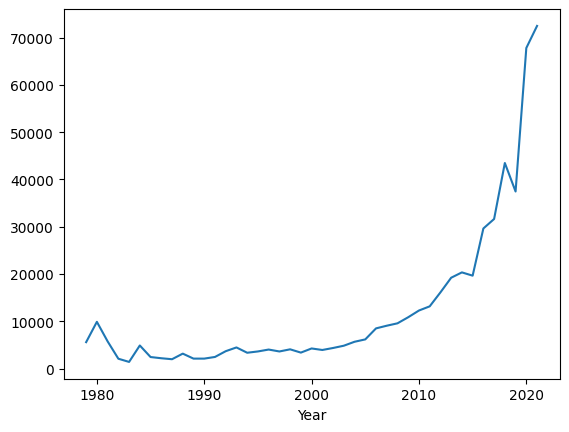

In [51]:
filter_df_by_year.plot(); plt.show()

Обратите внимание, что результат groupby имеет индексты - года!

In [52]:
filter_df_by_year.index

Index([1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990,
       1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002,
       2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014,
       2015, 2016, 2017, 2018, 2019, 2020, 2021],
      dtype='int64', name='Year')

Сделаем более приятный для чтения график

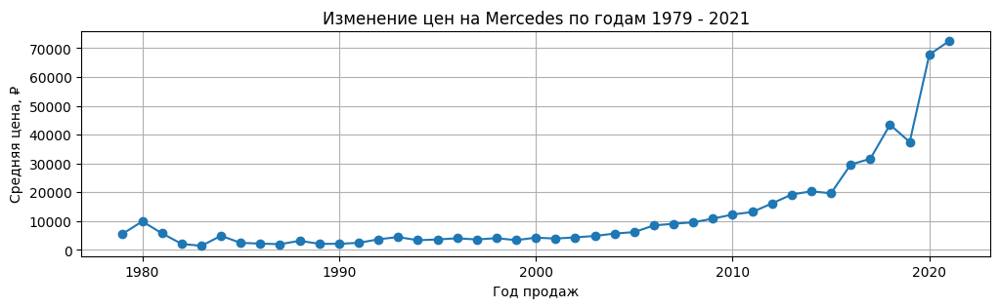

In [53]:
filter_df_by_year.plot(
    marker = 'o',
    figsize = (12,3),
    title = f'Изменение цен на {make} по годам {filter_df_by_year.index[0]} - {filter_df_by_year.index[-1]}',
    xlabel='Год продаж',
    ylabel='Средняя цена, ₽',
    color='tab:blue',
    grid=True
);

В более сложных случаях `pandas` представляет возможность построения таких графиокв, как гистограммы, графики рассеяния и другие типы графиков.

В примере ниже график типа 'bar chart' иллюстрирует среднюю цену автомобилей

In [172]:
# filter_df_by_year  = np.log(filter_df_by_year)

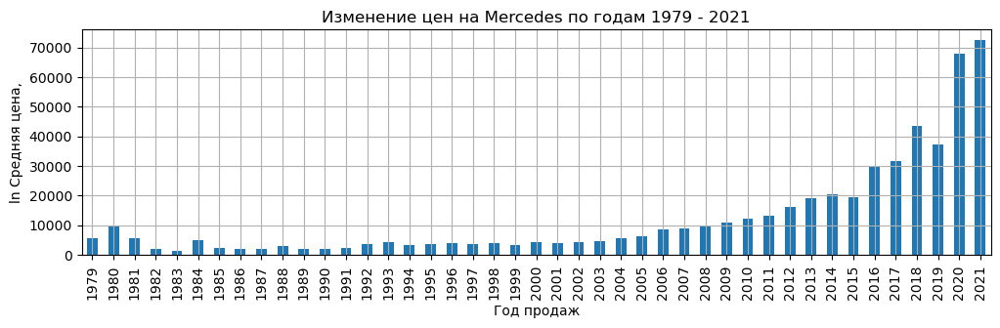

In [173]:

filter_df_by_year.plot(kind='bar',  
                       figsize = (12,3),
                       title = f'Изменение цен на {make} по годам {filter_df_by_year.index[0]} - {filter_df_by_year.index[-1]}',
                       xlabel='Год продаж',
                       ylabel='ln Средняя цена,',
                       color='tab:blue',
                       grid=True);

## matplotlib/seaborn

Более разнообразная и выразительная визуализация данных может быть полученна при помощи следующим библиотек.

__Matplotlib__ — предоставляет широкий спектр возможностей для создания статических графиков. Она обладает гибким API, позволяющим настраивать практически каждый аспект графика. Matplotlib поддерживает различные типы графиков, включая линейные графики, гистограммы, диаграммы рассеяния, столбчатые диаграммы, круговые диаграммы и многое другое. Основные преимущества [Matplotlib включают](https://external.software/archives/18540):
* Широкий спектр поддерживаемых типов графиков.
* Гибкость настройки внешнего вида графиков.
* Возможность создания публикаций высокого качества.
* Интеграция с другими библиотеками Python, такими как NumPy и Pandas.


__Seaborn__ — это библиотека Python, построенная на основе Matplotlib и предназначенная для статистической визуализации. Она предлагает более высокий уровень абстракции, что упрощает создание сложных статистических графиков, таких как диаграммы рассеяния с регрессионными линиями, графики распределения и тепловые карты. Основные преимущества Seaborn включают:
* Упрощение создания сложных статистических графиков.
* Интеграция с Pandas DataFrame.
* Автоматическая настройка стилей и цветовых палитр.
* Встроенные функции для визуализации распределений и взаимосвязей.



Реализация функции `plot` в `pandas` основана на библиотеке `matplotlib`.

Попробуем визуализировать аналогичный график - подсчет числа автомобилей для каждой марки 
при помощи `matplotlib`.



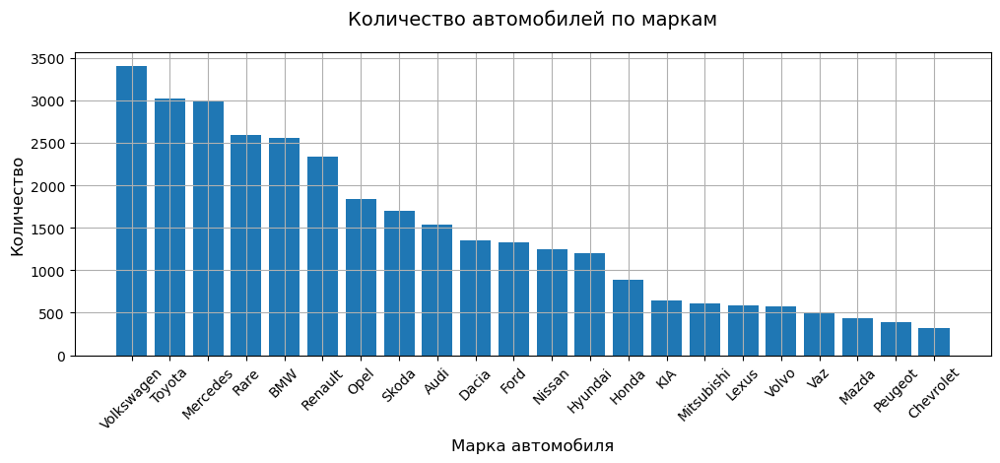

In [174]:
# Создание фигуры 
plt.figure(figsize=(12, 4))

# Создание barchat
data = df['Make'].value_counts()

plt.bar(data.index, data.values)

# Добавляем заголовки и подписи
plt.title('Количество автомобилей по маркам', fontsize=14, pad=20)
plt.xlabel('Марка автомобиля', fontsize=12)
plt.ylabel('Количество', fontsize=12)

plt.grid(True)

# делаем ось X красивой
plt.tick_params(axis='x', rotation=45, labelsize=10)



`Matplotlib` позволяет очень гибко настраивать графики. На графике можно изменить почти все, что угодно, но потребуется порыться в документации и найти нужные параметры.  

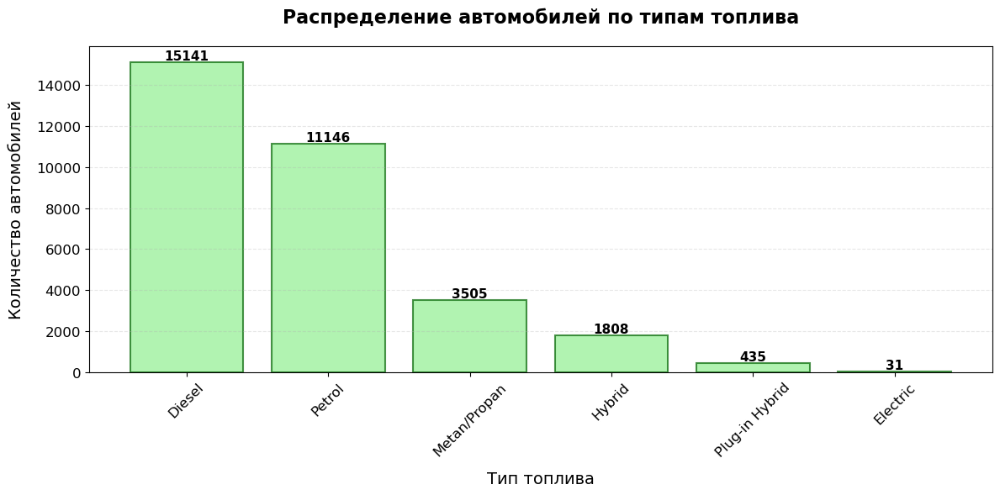

In [175]:
# Создаем фигуру и оси с указанием размера
plt.figure(figsize=(12, 6))

# Получаем количество автомобилей по типам топлива
# value_counts() автоматически сортирует по убыванию частоты
data = df['Fuel_type'].value_counts()

# Создаем столбчатую диаграмму с настройкой внешнего вида
bars = plt.bar(data.index, data.values, 
               color='lightgreen',      # Основной цвет столбцов
               edgecolor='darkgreen',   # Цвет границ столбцов
               alpha=0.7,               # Прозрачность (0-1)
               linewidth=1.5)           # Толщина границ

# НАСТРОЙКА ВНЕШНЕГО ВИДА ОСЕЙ:
# Поворачиваем подписи по оси X для лучшей читаемости
plt.tick_params(axis='x', rotation=45, labelsize=12)
# Настраиваем подписи по оси Y
plt.tick_params(axis='y', labelsize=12)

# ДОБАВЛЯЕМ ПОДПИСИ НАД СТОЛБЦАМИ:
# Проходим по каждому столбцу и добавляем текстовую метку
for bar in bars:
    height = bar.get_height()                    # Получаем высоту столбца
    plt.text(bar.get_x() + bar.get_width()/2.,   # Позиция X (центр столбца)
             height + 0.1,                       # Позиция Y (немного выше столбца)
             f'{int(height)}',                   # Текст (целое число)
             ha='center', va='bottom',           # Выравнивание по центру и снизу
             fontsize=11, fontweight='bold')     # Стиль шрифта

# ЗАГОЛОВКИ И ПОДПИСИ ОСЕЙ:
plt.title('Распределение автомобилей по типам топлива', 
          fontsize=16, pad=20, fontweight='bold')
plt.xlabel('Тип топлива', fontsize=14, labelpad=10)
plt.ylabel('Количество автомобилей', fontsize=14, labelpad=10)

# ДОБАВЛЯЕМ СЕТКУ ДЛЯ ЛУЧШЕЙ ЧИТАЕМОСТИ:
plt.grid(axis='y',    # Сетка только по вертикали (ось Y)
         alpha=0.3,   # Прозрачность сетки
         linestyle='--')  # Стиль линии (пунктир)

# АВТОМАТИЧЕСКИ НАСТРАИВАЕМ ОТСТУПЫ ДЛЯ КРАСИВОГО ОТОБРАЖЕНИЯ
plt.tight_layout()

# ОТОБРАЖАЕМ ГРАФИК
plt.show()

Могут быть и более сложные графики. Например рассмотрим графики гистограмм 

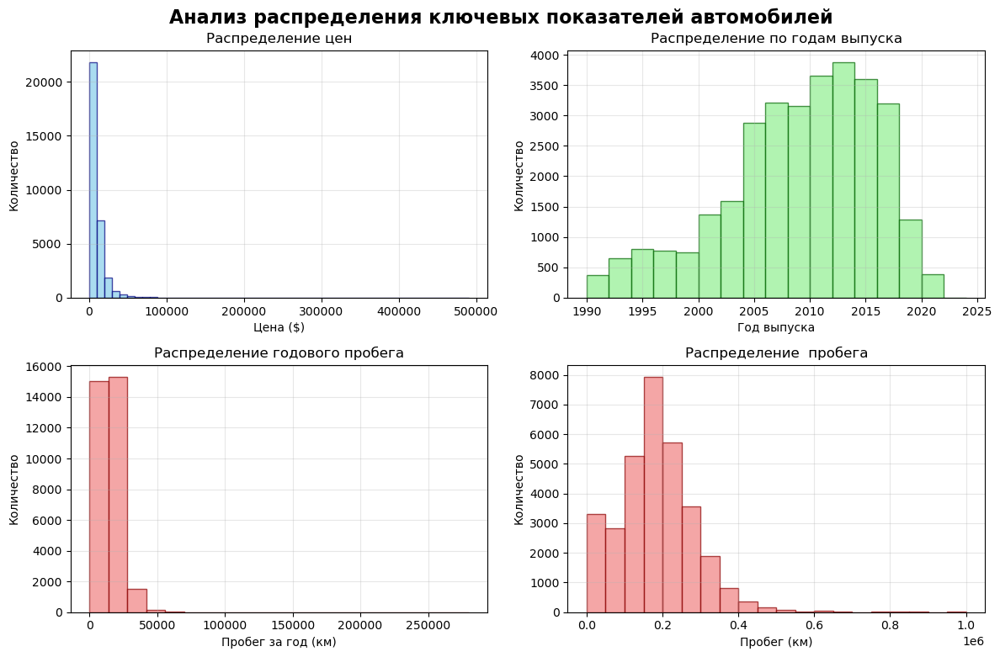

In [176]:
# Создаем фигуру с несколькими subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Анализ распределения ключевых показателей автомобилей', 
             fontsize=16, fontweight='bold', y=0.97)

# Гистограмма цен
axes[0,0].hist(df['Price'], bins=50, color='skyblue', edgecolor='navy', alpha=0.7)
axes[0,0].set_title('Распределение цен')
axes[0,0].set_xlabel('Цена ($)')
axes[0,0].set_ylabel('Количество')
axes[0,0].grid(alpha=0.3)

# Гистограмма годов
axes[0,1].hist(df['Year'], bins=range(1990, 2025, 2), color='lightgreen', 
               edgecolor='darkgreen', alpha=0.7)
axes[0,1].set_title('Распределение по годам выпуска')
axes[0,1].set_xlabel('Год выпуска')
axes[0,1].set_ylabel('Количество')
axes[0,1].grid(alpha=0.3)

# Гистограмма пробега в год
km_filtered = df['km_year']
axes[1,0].hist(km_filtered, bins=20, color='lightcoral', 
               edgecolor='darkred', alpha=0.7)
axes[1,0].set_title('Распределение годового пробега')
axes[1,0].set_xlabel('Пробег за год (км)')
axes[1,0].set_ylabel('Количество')
axes[1,0].grid(alpha=0.3)

# Гистограмма зависимости цены от пробега (hexbin)
km_ = df['Distance']
axes[1,1].hist(km_, bins=20, color='lightcoral', 
               edgecolor='darkred', alpha=0.7)
axes[1,1].set_title('Распределение  пробега')
axes[1,1].set_xlabel('Пробег (км)')
axes[1,1].set_ylabel('Количество')
axes[1,1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Поскольку насторйка нужного графика в `matplotlib` требует очень много кода, в котором не сложно ошибится и можент получится не то, что хочется, для отдельных приложений визуализации существуют свои библиотеки. Так для визуализации больших данных могут быть найдены шаблоны в бибилотеке `seaborn` (`sns`). Отметим, что примеры готовых шаблонов seaborn можно найти в [галерее на официальном сайте библиотеки.](https://seaborn.pydata.org/examples/index.html).

Посторим гистограмму года выпуска

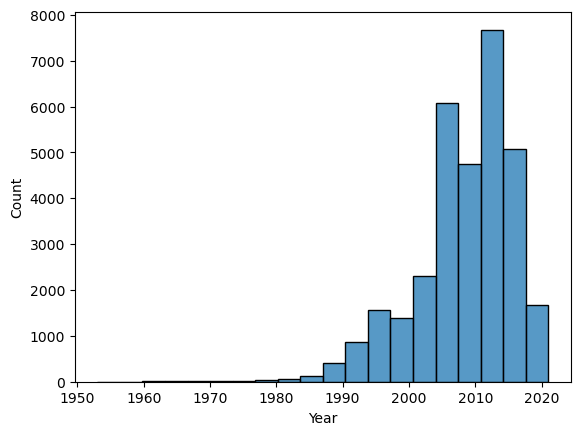

In [177]:
sns.histplot(data=df, x='Year', bins = 20);

Столбцы имеют явные аномалии, особенно Distance и Price(euro). Чтобы лучше понять эти аномалии посмотрим на столбцы в логарифмическом масштабе.

Оценим распределение по пробегу за год и попробуем его аппроксимировать

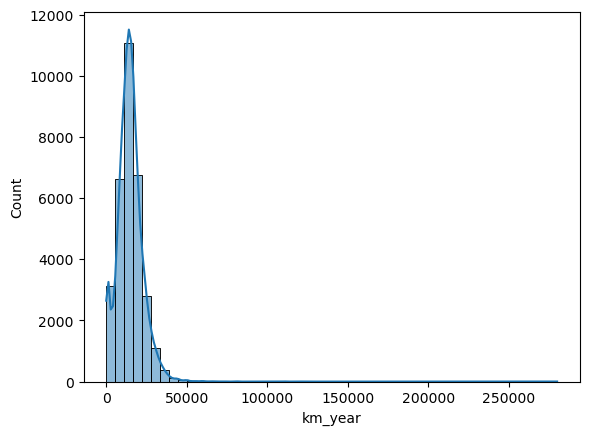

In [178]:
sns.histplot(df['km_year'], bins = 50, kde=True);

Визуализируем гистограмму пробега с разделением по типу трансмиссии.

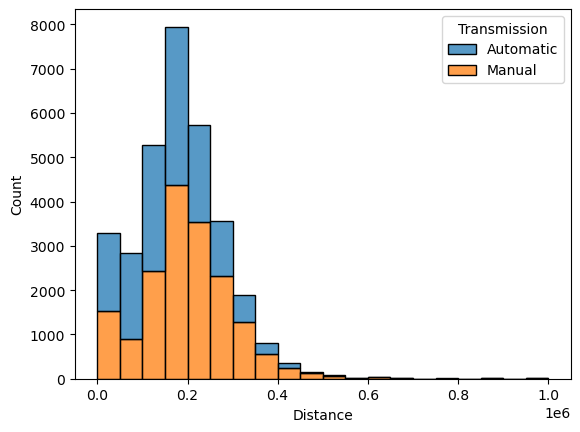

In [179]:
sns.histplot(data=df, x='Distance', hue='Transmission', multiple='stack', bins = 20);

Графики попробегу и в год и по годам явно показывают, что года до 1950 и пробеги  за 100 000 не достаточно представлены в выборке и скорее не смогут помочь в задаче повышения качества предсказаний.

Однако, для более точного анализа выборосов в указанных факторах попробуем построить их в виде т.н. `boxplots`

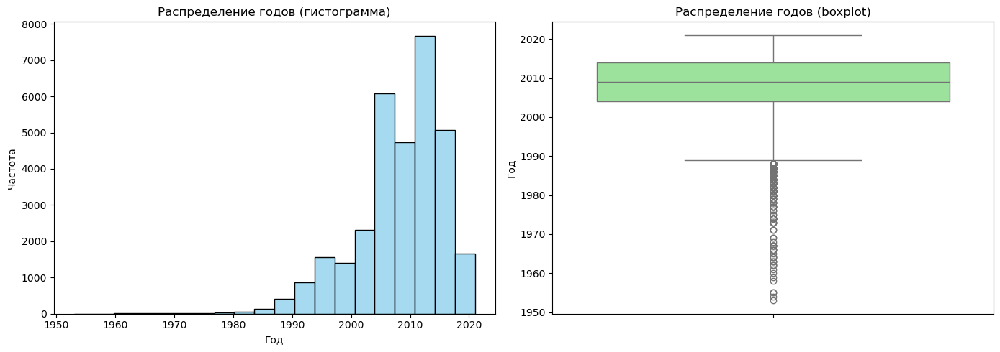

In [180]:
# Создаём фигуру с двумя подграфиками (1 строка, 2 столбца)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма
sns.histplot(data=df, x='Year', bins=20, kde=False, ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title('Распределение годов (гистограмма)')
axes[0].set_xlabel('Год')
axes[0].set_ylabel('Частота')

# Boxplot
sns.boxplot(data=df, y='Year', ax=axes[1], color='lightgreen')
axes[1].set_title('Распределение годов (boxplot)')
axes[1].set_ylabel('Год')
axes[1].set_xlabel('')

# Улучшаем отображение
plt.tight_layout()
plt.show()

[`Box plot`](https://habr.com/ru/companies/ods/articles/323210/) состоит из коробки (поэтому он и называется `box plot`), усиков и точек. Коробка показывает т.н.
"интерквартильный размах распределения", то есть соответственно диапазон куда попадают отсортированныне значения от  $25\%$ (`Q1`) до $75\%$ (`Q3`) от всего объема выборки (`перцентили`). Черта внутри коробки обозначает __медиану__ распределения ($50\%$).

С коробкой разобрались, перейдем к усам. __Усы__ отображают весь разброс точек кроме выбросов, то есть минимальные и максимальные значения, которые попадают в промежуток ($Q1 - 1.5*IQR, Q3 + 1.5*IQR$), где $IQR = Q3 - Q1$ — интерквартильный размах. Точками на графике обозначаются выбросы (__outliers__) — те значения, которые не вписываются в промежуток значений, заданный усами графика.

Другимисловами, все что достаточно далко от усов - это выбросы. На графике справа мы видем, что такие выбросы вероятно соотвествуют годам от 1970 и ниже.

Попробуем убрать такие выбрасы и посмотреть на новое распределние.

In [181]:
question_year = df[df.Year < 1971]
df = df.drop(question_year.index)

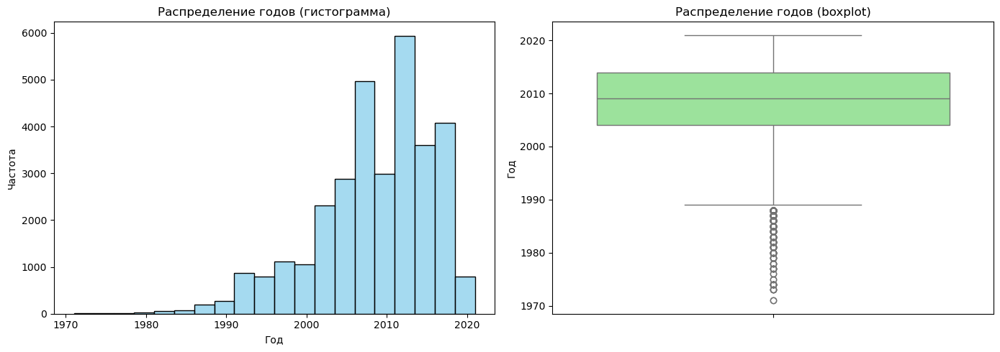

In [182]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма
sns.histplot(data=df, x='Year', bins=20, kde=False, ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title('Распределение годов (гистограмма)')
axes[0].set_xlabel('Год')
axes[0].set_ylabel('Частота')

# Boxplot
sns.boxplot(data=df, y='Year', ax=axes[1], color='lightgreen')
axes[1].set_title('Распределение годов (boxplot)')
axes[1].set_ylabel('Год')
axes[1].set_xlabel('')

# Улучшаем отображение
plt.tight_layout()
plt.show()

Попробуем теперь провести аналогичный box plot анализ для всех численных колонок

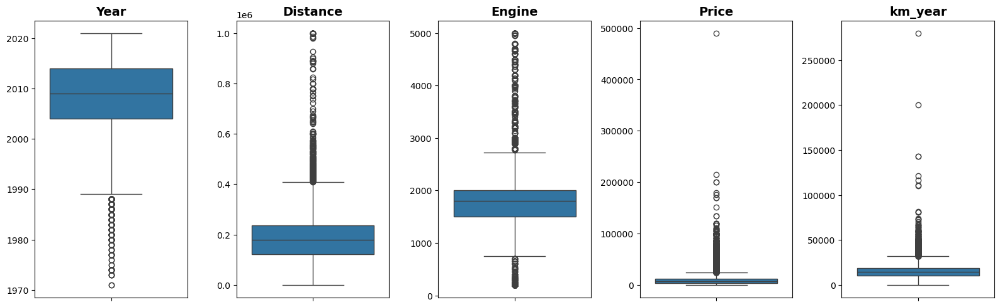

In [183]:
fig, axes = plt.subplots(1, 5, figsize=(16, 5))

for i, col in enumerate(num_columns):
    sns.boxplot(data=df, y=col, ax=axes[i], color='tab:blue')
    axes[i].set_title(f'{col}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('')  # Убираем подпись X (она не нужна для вертикального boxplot)
    axes[i].set_ylabel('')
plt.tight_layout()
plt.show()

In [184]:
question_ = df[df['Distance'] >= 8e5]
df = df.drop(question_.index)

question_ = df[df['Price'] >= 1.2e5]
df = df.drop(question_.index)

question_ = df[df['km_year'] >= 8e4]
df = df.drop(question_.index)


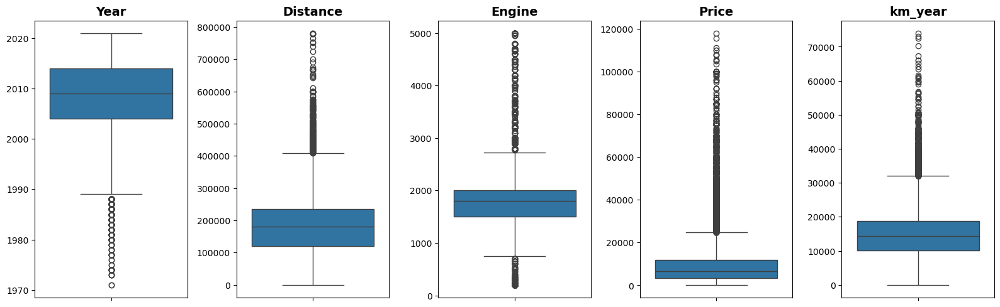

In [185]:
fig, axes = plt.subplots(1, 5, figsize=(16, 5))

for i, col in enumerate(num_columns):
    sns.boxplot(data=df, y=col, ax=axes[i], color='tab:blue')
    axes[i].set_title(f'{col}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('')  # Убираем подпись X (она не нужна для вертикального boxplot)
    axes[i].set_ylabel('')
plt.tight_layout()
plt.show()

### Анализ совместного поведения данных

Иногда анлиза только одного параметра не достаточно, чтобы понять есть ли аномалии в данных. Аномалии могут проявляться во взаимном поведении переменных. Давайте попробуем постоить несколько вариантов визуализации совместного поведения нескольких переменнных.

 Построим пару вариантов визуализации совместного поведения параметров 


Попробуем тип визуализации  `scatter plot`:
* каждая точка - это одна запись в наших данных;
* покрасим точки в разный цвет по типу трасмиссии;
*  размер точек будет говорить о пробеге в год.

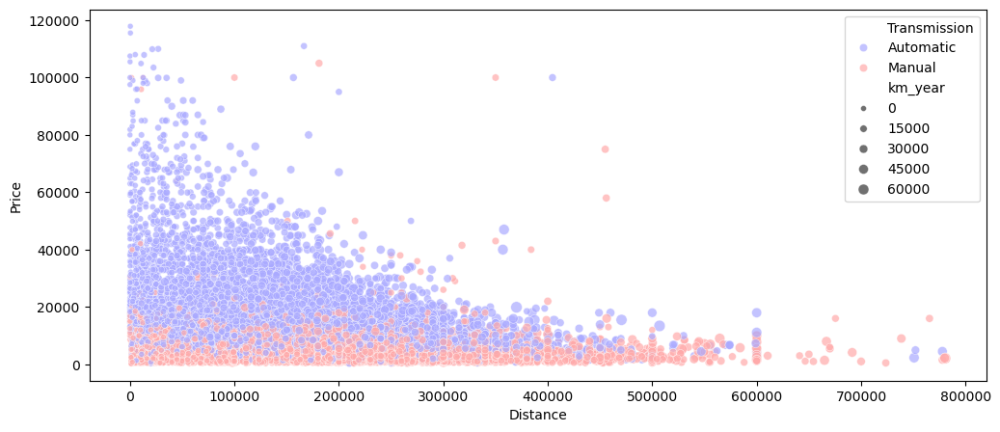

In [186]:
plt.figure(figsize=(12,5))
sns.scatterplot(    
    data=df,
    x="Distance", 
    y="Price",
    hue="Transmission", 
    size = "km_year", 
    alpha = 0.7,
    palette='bwr'
    );

И так, видно, что:
* большинство автомобмилей лежат в нижнем левом триугольние;
* цена ав автомобили с автоматической трансмиссией явно выше чем с ручной (это и ожидаемо);
* есть ряд автомобилей с явно завышенным соотношением цен и пробега, при этом даже с небольшим пробегом в год;
* автомобили с ценой выше 40 000 и пробегом выше 300 000 редкие;
* автомобили с ценой выше 60 000 и пробегом выше 150 000 редкие;
* пробеги для автоматической трансмиссии выше 700 000 редкие;
* цена для ручной трансмиссии выше 80 000 редкая.

Редкие случаи также можно отфильтровать.

In [187]:
question_ = df[(df['Distance'] >= 7e5)&(df['Transmission']=='Automatic')]
df = df.drop(question_.index)

question_ = df[(df['Price'] >= 8e4)&(df['Transmission']=='Manual')]
df = df.drop(question_.index)

question_ = df[(df['Price'] >= 4e4)&(df['Distance']>=300_000)]
df = df.drop(question_.index)

question_ = df[(df['Price'] >= 6e4)&(df['Distance']>=150_000)]
df = df.drop(question_.index)



# question_ = df[(df['Price'] >= 8e4)&(df['Transmission']=='Manual')]
# df = df.drop(question_.index)


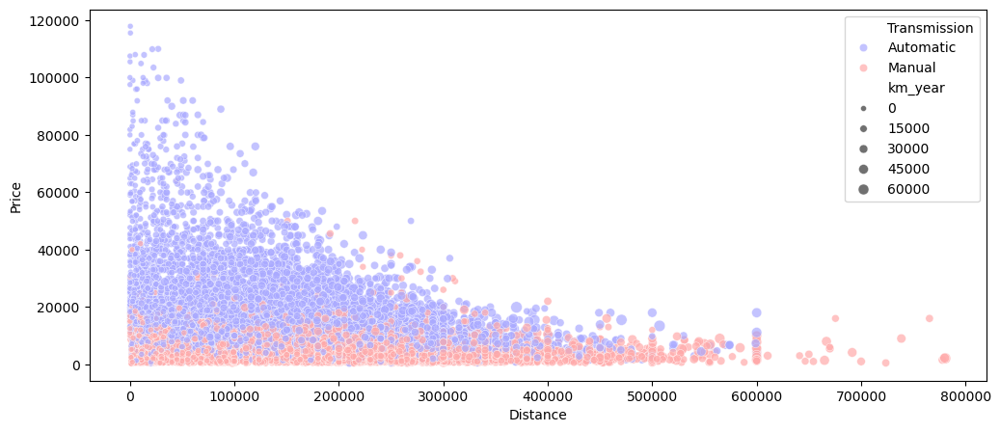

In [188]:
plt.figure(figsize=(12,5))
sns.scatterplot(    
    data=df,
    x="Distance", 
    y="Price",
    hue="Transmission", 
    size = "km_year", 
    alpha = 0.7,
    palette='bwr'
    );

### Упражнения 
1. провести очистку редких случая по параметрам: средняя цена автомобиля в год, соотношение средней цена и года выпуска/пробега.
2. предложить еще не менее 2х параметров к графическому анализу.
   

## Визуализация категориальные данные
Отметим, что по мимо численных данных визуализация может быть предложена и для категориальных данных. Так в примере ниже показаны результаты визуализации среднего  пробега автомобиля по марке.

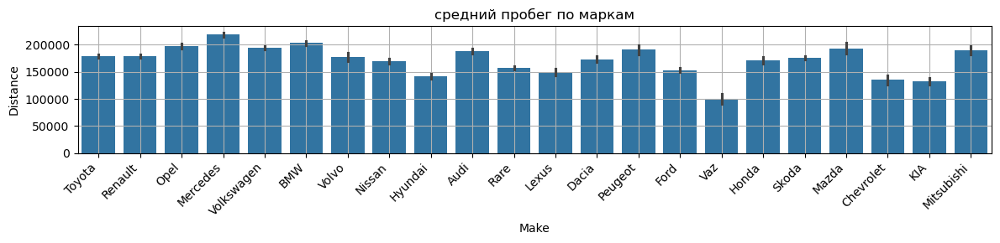

In [189]:
plt.figure(figsize= (12,3))

sns.barplot(data=df, x='Make', y='Distance')


plt.grid(True)
plt.xticks(rotation=45, ha='right')  # ha='right' — чтобы подписи не "уезжали"
plt.title('средний пробег по маркам')
plt.tight_layout()  # важно: предотвращает обрезание подписей
plt.show()

Более выразительным в таких случаях будет использования `boxplot` 

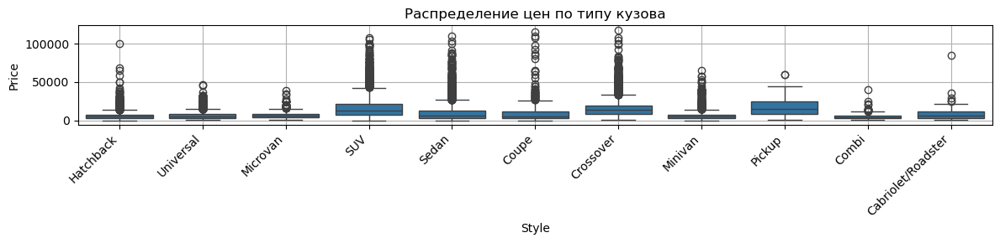

In [190]:
plt.figure(figsize= (12,3))

sns.boxplot(data=df, x='Style', y='Price')

plt.grid(True)
plt.xticks(rotation=45, ha='right')  # ha='right' — чтобы подписи не "уезжали"
plt.title('Распределение цен по типу кузова')
plt.tight_layout()  # важно: предотвращает обрезание подписей
plt.show()

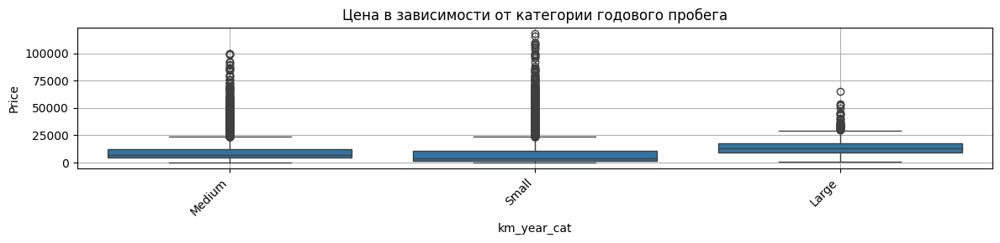

In [51]:
plt.figure(figsize= (12,3))

sns.boxplot(data=df, x='km_year_cat', y='Price');
plt.grid(True)
plt.xticks(rotation=45, ha='right')  # ha='right' — чтобы подписи не "уезжали"
plt.title('Цена в зависимости от категории годового пробега')
plt.tight_layout()  # важно: предотвращает обрезание подписей
plt.show()



Для более детального анализа категориальнх переменных попробуем также `catplot` - то есть набор boxplot по производителям

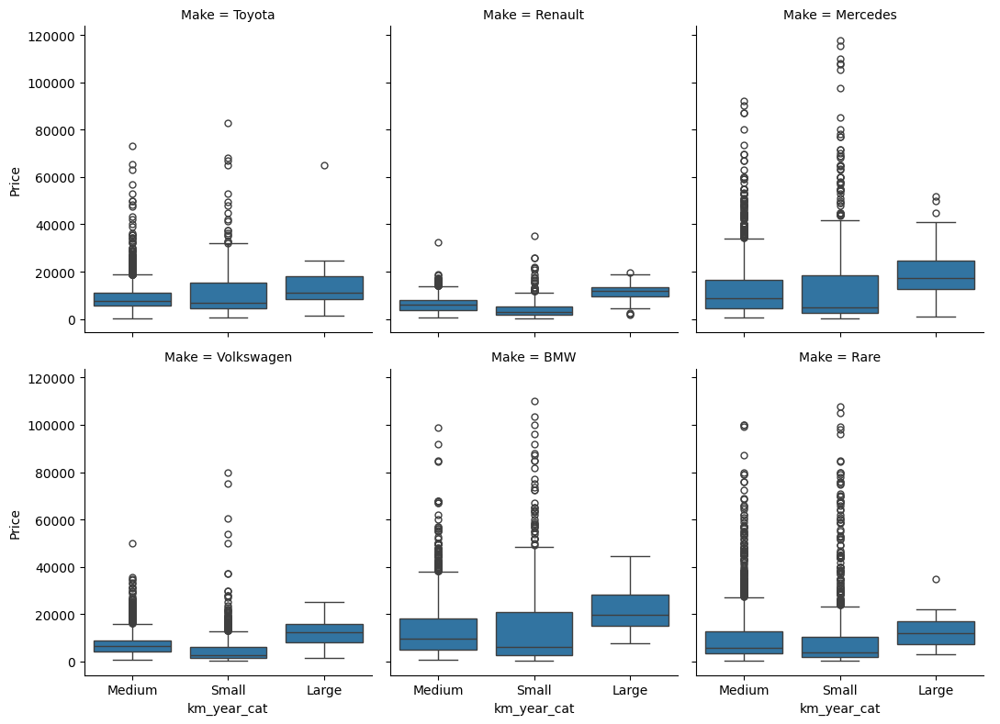

In [52]:
# Берём топ-6 брендов
top_makes = df['Make'].value_counts().head(6).index
df_top = df[df['Make'].isin(top_makes)]

sns.catplot(
    x='km_year_cat',
    y='Price',
    col='Make',
    data=df_top.dropna(subset=['km_year_cat', 'Price']),
    kind='box',
    col_wrap=3,
    height=4,
    aspect=0.9
)
plt.tight_layout()
plt.show()

Из нашего анализа также видно, что есть автомобиле с завышенной ценой.

Визуализация может быть проведена также и для сводных таблиц.

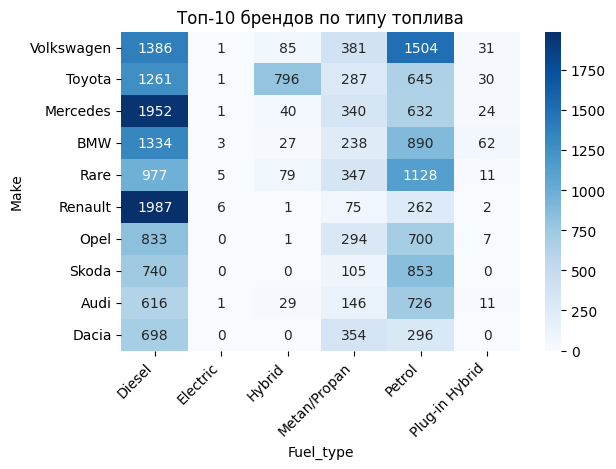

In [53]:
fuel_by_make = pd.crosstab(df['Make'], df['Fuel_type'])

fuel_by_make = fuel_by_make.loc[fuel_by_make.sum(axis=1).nlargest(10).index]  # топ-10 брендов

sns.heatmap(fuel_by_make, annot=True, fmt='d', cmap='Blues')
plt.title('Топ-10 брендов по типу топлива')
plt.xticks(rotation=45, ha='right')  # ha='right' — чтобы подписи не "уезжали"
plt.tight_layout()  # важно: предотвращает обрезание подписей
plt.show()

### Упражнение
1. Предлагает провести доочистку данных по результатам визуализации категориальных данных
1. Из визуализированной сводной таблицы хорошо видно, что типы Electric, Hybrid и Plug-in Hybrid следовало бы объеденить в общий тип. Однако, чтобы точно в этом убедится нужно проверить как эти типы распределены по остальным параметрам. Предлагается сделать это упражнение самостоятельно.

In [62]:
df.to_csv('cars_cleaned.csv')
df[num_columns].to_csv('cars_cleaned_num.csv')

# Интерактивная визуализация

__Plotly__ — это библиотека Python, предназначенная для интерактивной визуализации данных. Она позволяет создавать интерактивные графики, 3D-графики и географические карты, которые можно встраивать в веб-приложения и дашборды. Основные преимущества Plotly включают:
* Интерактивность: графики можно масштабировать, перемещать и настраивать с помощью мыши.
* Веб-ориентированность: графики можно встраивать в веб-приложения и дашборды.
* Поддержка различных типов графиков, включая 3D-графики и географические карты.
* Простота создания интерактивных дашбордов.

Примеры интерактивных визуализаций могут быть найдены [в галерее на официальном сайте](https://plotly.com/python/).

## Базовый __plotly__

Проведем подготовку - импорт

In [191]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

 Интерактивный scatter plot: Цена vs Год + цвет по бренду. Такая визуализация покажет, как цена зависит от года, и какие бренды «дороже». 

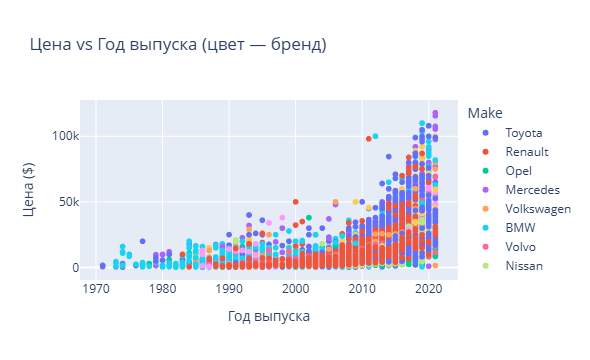

In [192]:
fig = px.scatter(
    df,
    x='Year',
    y='Price',
    color='Make',
    hover_data=['Model', 'Distance', 'Fuel_type', df.index], 
    title='Цена vs Год выпуска (цвет — бренд)',
    labels={'Price': 'Цена ($)', 'Year': 'Год выпуска'}
)
fig.update_layout(height=600)
fig.show()

Визуализация показывает несколько еще не отфильтрованных выбросов. Есил навести на каждый из них, то мы увидим их индекс и другие параметры. 

Ниже показаны интерактивные `boxplot` с распределением цены по трансмиссии и типу двиготеля 

In [57]:
df_with_index = df.copy()
df_with_index['index_'] = df_with_index.index

fig = px.box(
    df_with_index,
    x='Fuel_type',
    y='Price',
    color='Transmission',
    hover_data=['index_', 'Make', 'Model'],  # ← индекс и другая полезная инфа
    title='Цена по типу топлива и коробке передач (наведите на выбросы)',
    labels={'Price': 'Цена ($)', 'Fuel_type': 'Тип топлива'}
)
fig.update_layout(height=500)
fig.show()

Видим, что осталась еще несколько недочищенных точек. 

In [58]:
# Добавляем индекс как колонку
df_with_index = df.copy()
df_with_index['ID'] = df_with_index.index

fig = px.histogram(
    df_with_index,
    x='Price',
    color='km_year_cat',
    marginal='rug',  # ← rug показывает каждую точку
    hover_data=['ID', 'Make', 'Model'],  # ← индекс и другая инфа
    opacity=0.7,
    nbins=50,
    title='Распределение цен по категориям годового пробега (наведите на точки внизу)'
)
fig.update_layout(bargap=0.1)
fig.show()

### Упражнение 
1. провести доочистку данных при помощи интерактивных визуализаций

сохраните результат

In [ ]:
df.to_csv('cars_cleaned.csv')

## Для справки еще более сложные визуализации

Могут быть и более изветвленные визуализации, пример одной из которых показан ниже.

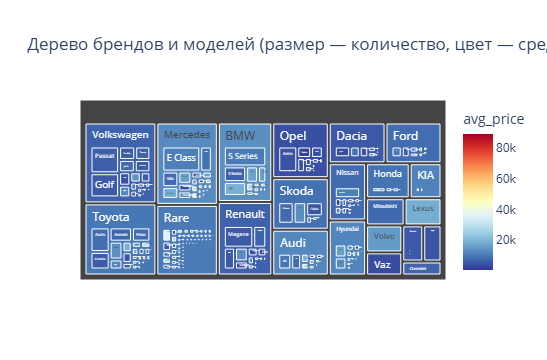

In [271]:
model_stats = df.groupby(['Make', 'Model']).agg(
    avg_price=('Price', 'mean'),
    count=('Price', 'size')
).reset_index()

fig = px.treemap(
    model_stats,
    path=['Make', 'Model'],
    values='count',
    color='avg_price',
    color_continuous_scale='RdYlBu_r',
    title='Дерево брендов и моделей (размер — количество, цвет — средняя цена)'
)
fig.show()

In [1]:
import pandas as pd
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output

# === 1. Подготовка данных ===
df_viz = df.copy()
df_viz['ID'] = df_viz.index  # добавляем ID

# Уникальные категории для фильтров
makes = ['(Все)'] + sorted(df_viz['Make'].dropna().unique().tolist())
fuel_types = ['(Все)'] + sorted(df_viz['Fuel_type'].dropna().unique().tolist())
transmissions = ['(Все)'] + sorted(df_viz['Transmission'].dropna().unique().tolist())
km_cats = ['(Все)'] + sorted(df_viz['km_year_cat'].dropna().unique().tolist())

# === 2. Виджеты фильтров ===
make_widget = widgets.Dropdown(options=makes, value='(Все)', description='Бренд:')
fuel_widget = widgets.Dropdown(options=fuel_types, value='(Все)', description='Топливо:')
trans_widget = widgets.Dropdown(options=transmissions, value='(Все)', description='Коробка:')
km_widget = widgets.Dropdown(options=km_cats, value='(Все)', description='Пробег/год:')

# === 3. Функция обновления графика и таблицы ===
output = widgets.Output()

def update_plot(change=None):
    # Фильтрация
    filtered = df_viz.copy()
    
    if make_widget.value != '(Все)':
        filtered = filtered[filtered['Make'] == make_widget.value]
    if fuel_widget.value != '(Все)':
        filtered = filtered[filtered['Fuel_type'] == fuel_widget.value]
    if trans_widget.value != '(Все)':
        filtered = filtered[filtered['Transmission'] == trans_widget.value]
    if km_widget.value != '(Все)':
        filtered = filtered[filtered['km_year_cat'] == km_widget.value]
    
    # Очистка вывода
    with output:
        clear_output(wait=True)
        
        if filtered.empty:
            print("Нет данных по выбранным фильтрам.")
            return
        
        # Построение графика
        fig = px.scatter(
            filtered,
            x='Year',
            y='Price',
            color='Make',
            hover_data=['ID', 'Model', 'Distance', 'Engine', 'Fuel_type', 'Transmission'],
            title=f'Найдено записей: {len(filtered)}',
            labels={'Price': 'Цена ($)', 'Year': 'Год выпуска'}
        )
        fig.update_layout(height=500, showlegend=False)
        fig.show()
        
        # Вывод таблицы (первые 10 записей)
        display(filtered[['ID', 'Make', 'Model', 'Year', 'Price', 'Distance']].head(10))

# === 4. Привязка событий и запуск ===
make_widget.observe(update_plot, names='value')
fuel_widget.observe(update_plot, names='value')
trans_widget.observe(update_plot, names='value')
km_widget.observe(update_plot, names='value')

# Отображение интерфейса
controls = widgets.VBox([
    widgets.HTML("<h3>Фильтры для анализа автомобилей</h3>"),
    widgets.HBox([make_widget, fuel_widget]),
    widgets.HBox([trans_widget, km_widget])
])

display(controls)
update_plot()  # первый запуск
display(output)

NameError: name 'df' is not defined